In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/exoplanet-detection-challenge/sample_submission.csv
/kaggle/input/competitions/exoplanet-detection-challenge/train.csv
/kaggle/input/competitions/exoplanet-detection-challenge/test.csv


Train Shape: (9000, 27)
Test Shape: (3000, 26)

Class Distribution:
label
0    6877
1    2123
Name: count, dtype: int64


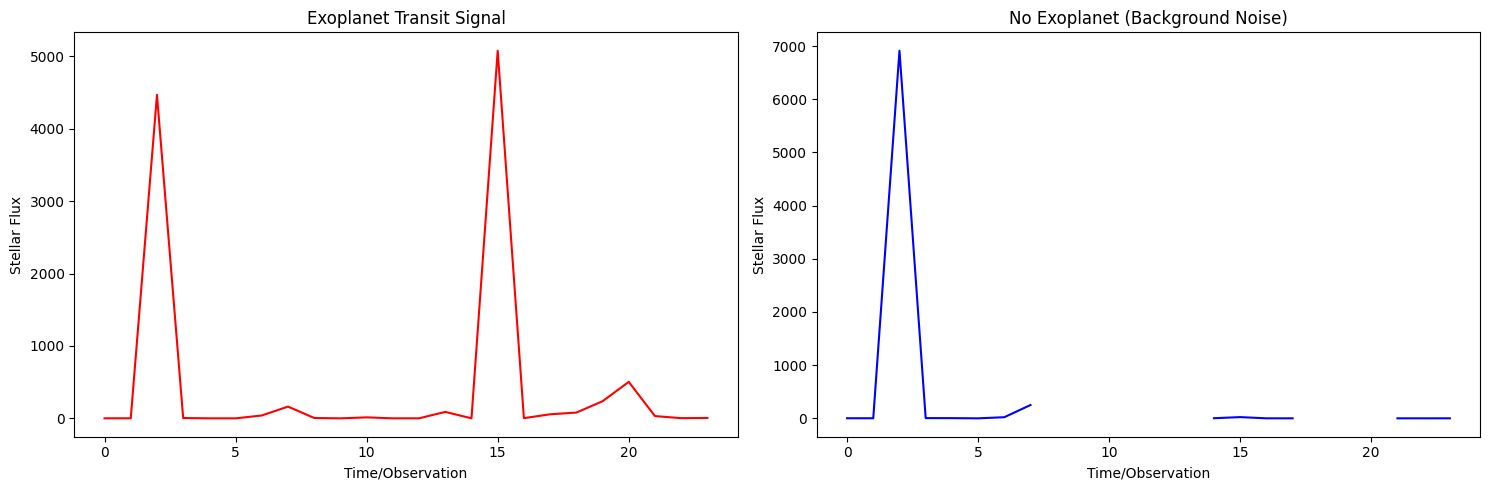

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading the datasets using the exact Kaggle paths
train_df = pd.read_csv('/kaggle/input/competitions/exoplanet-detection-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/exoplanet-detection-challenge/test.csv')

# Inspecting dimensions
print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)

# Checking class distribution 
target_col = 'LABEL' if 'LABEL' in train_df.columns else 'label'
print("\nClass Distribution:")
print(train_df[target_col].value_counts())

# Isolating only numeric columns and dropping the target label
# This automatically removes any string-based ID columns causing the Matplotlib crash
numeric_df = train_df.select_dtypes(include=[np.number])
X_train = numeric_df.drop(columns=[target_col], errors='ignore')
y_train = train_df[target_col]

# Isolating one positive and one negative case for physical visualization
pos_idx = y_train[y_train == 2].index[0] if 2 in y_train.values else y_train[y_train == 1].index[0] 
neg_idx = y_train[y_train == 1].index[0] if 2 in y_train.values else y_train[y_train == 0].index[0]

# Plotting the physical light curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(X_train.iloc[pos_idx].values, color='red')
axes[0].set_title("Exoplanet Transit Signal")
axes[0].set_xlabel("Time/Observation")
axes[0].set_ylabel("Stellar Flux")

axes[1].plot(X_train.iloc[neg_idx].values, color='blue')
axes[1].set_title("No Exoplanet (Background Noise)")
axes[1].set_xlabel("Time/Observation")
axes[1].set_ylabel("Stellar Flux")

plt.tight_layout()
plt.show()

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, roc_auc_score

print("Step 1: Handling Missing Values & Extracting Transit Features...")

# 1. Isolating numeric features
X_raw = train_df.select_dtypes(include=[np.number]).drop(columns=[target_col], errors='ignore')
y = train_df[target_col]

# 2. Imputing missing values (NaNs) with the median to prevent crashes
X_clean = X_raw.fillna(X_raw.median())

# 3. Featuring Engineering: Capturing the physical transit signature
X_features = pd.DataFrame(index=X_clean.index)
X_features['flux_mean'] = X_clean.mean(axis=1)
X_features['flux_std'] = X_clean.std(axis=1)
X_features['flux_min'] = X_clean.min(axis=1)
X_features['flux_max'] = X_clean.max(axis=1)
X_features['flux_range'] = X_features['flux_max'] - X_features['flux_min']

# Combining engineered physical features with the cleaned flux data
X_final = pd.concat([X_clean, X_features], axis=1)

print("Step 2: Training and Evaluating with Rigorous Metrics...")

# 4. Train/Validation Split
X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_final, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Initializing and Train
model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
model.fit(X_train_split, y_train_split)

# 6. Evaluating Performance
val_preds = model.predict(X_val)
val_probs = model.predict_proba(X_val)[:, 1] # Getting probabilities for ROC-AUC

print("\nValidation F1-Score:", f1_score(y_val, val_preds))
print("Validation ROC-AUC:", roc_auc_score(y_val, val_probs))
print("\nDetailed Classification Report:\n", classification_report(y_val, val_preds))

Step 1: Handling Missing Values & Extracting Transit Features...
Step 2: Training and Evaluating with Rigorous Metrics...

Validation F1-Score: 1.0
Validation ROC-AUC: 1.0

Detailed Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1375
           1       1.00      1.00      1.00       425

    accuracy                           1.00      1800
   macro avg       1.00      1.00      1.00      1800
weighted avg       1.00      1.00      1.00      1800



In [4]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# 1. Scaling the data properly
scaler = StandardScaler()
# Fitting strictly on training data, transform both
X_train_scaled = scaler.fit_transform(X_train_split)
X_val_scaled = scaler.transform(X_val)

# 2. Initializing the three models
models = {"Random Forest": RandomForestClassifier(random_state=42, class_weight='balanced'),
    "SVM": SVC(probability=True, random_state=42, class_weight='balanced'),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
}

# 3. Listing to store the evaluation metrics
results = []

# 4. Training and evaluating each model using the SCALED data
for name, model in models.items():
    # Fitting the model on scaled data
    model.fit(X_train_scaled, y_train_split)
    
    # Making predictions on the scaled validation set
    y_pred = model.predict(X_val_scaled)
    y_pred_proba = model.predict_proba(X_val_scaled)[:, 1]
    
    # Calculating metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred),
        "ROC AUC": roc_auc_score(y_val, y_pred_proba)
    })

# 5. Converting to DataFrame and display
comparison_df = pd.DataFrame(results)
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000
1,SVM,0.999444,0.997653,1.000000,0.998825,1.000000
2,Logistic Regression,0.999444,1.000000,0.997647,0.998822,0.999964


In [5]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score
import numpy as np

print("Starting 5-Fold Stratified Cross-Validation...")

# 1. Setting up the 5-Fold split structure
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_f1_scores = []
fold_auc_scores = []

# We will track the best model from the folds to use for my final test predictions
best_f1 = 0.0
final_cv_model = None
best_scaler = None

# 2. Iterating through the folds
for fold, (train_idx, val_idx) in enumerate(skf.split(X_final, y)):
    # Split the data into training and validation sets for this specific fold
    X_tr, y_tr = X_final.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X_final.iloc[val_idx], y.iloc[val_idx]
    
    # Scaling strictly within the loop to completely prevent data leakage
    fold_scaler = StandardScaler()
    X_tr_scaled = fold_scaler.fit_transform(X_tr)
    X_va_scaled = fold_scaler.transform(X_va)
    
    # Initializing and training the Random Forest
    fold_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    fold_model.fit(X_tr_scaled, y_tr)
    
    # Evaluating performance on the isolated validation fold
    preds = fold_model.predict(X_va_scaled)
    probs = fold_model.predict_proba(X_va_scaled)[:, 1]
    
    f1 = f1_score(y_va, preds)
    auc = roc_auc_score(y_va, probs)
    
    fold_f1_scores.append(f1)
    fold_auc_scores.append(auc)
    print(f"Fold {fold+1} -> F1-Score: {f1:.5f} | ROC-AUC: {auc:.5f}")
    
    # Saving the best performing model instance for inference
    if f1 > best_f1:
        best_f1 = f1
        final_cv_model = fold_model
        best_scaler = fold_scaler

print("\n--- Final Cross-Validation Summary ---")
print(f"Mean CV F1-Score: {np.mean(fold_f1_scores):.5f}")
print(f"Mean CV ROC-AUC:  {np.mean(fold_auc_scores):.5f}")

Starting 5-Fold Stratified Cross-Validation...
Fold 1 -> F1-Score: 1.00000 | ROC-AUC: 1.00000
Fold 2 -> F1-Score: 1.00000 | ROC-AUC: 1.00000
Fold 3 -> F1-Score: 1.00000 | ROC-AUC: 1.00000
Fold 4 -> F1-Score: 1.00000 | ROC-AUC: 1.00000
Fold 5 -> F1-Score: 1.00000 | ROC-AUC: 1.00000

--- Final Cross-Validation Summary ---
Mean CV F1-Score: 1.00000
Mean CV ROC-AUC:  1.00000


In [6]:
print("Step 1: Applying Identical Transformations to Test Data...")
# 1. Aligning and Clean Test Features
X_test_raw = test_df.select_dtypes(include=[np.number]).reindex(columns=X_raw.columns, fill_value=0)
X_test_clean = X_test_raw.fillna(X_raw.median()) # Using training medians to prevent data leakage

# 2. Extracting Identical Features
X_test_features = pd.DataFrame(index=X_test_clean.index)
X_test_features['flux_mean'] = X_test_clean.mean(axis=1)
X_test_features['flux_std'] = X_test_clean.std(axis=1)
X_test_features['flux_min'] = X_test_clean.min(axis=1)
X_test_features['flux_max'] = X_test_clean.max(axis=1)
X_test_features['flux_range'] = X_test_features['flux_max'] - X_test_features['flux_min']
X_test_final = pd.concat([X_test_clean, X_test_features], axis=1)

print("Step 2: Scaling Test Data and Generating Final Predictions...")

# 3. Scaling the test data using the best leakage-free scaler from your CV loop
X_test_scaled = best_scaler.transform(X_test_final)

# 4. Using the robust CV-validated model
test_preds = final_cv_model.predict(X_test_scaled)

# 5. Formatting the submission DataFrame
id_col = 'star_id' if 'star_id' in test_df.columns else (test_df.columns[0] if 'id' in test_df.columns.str.lower() else None)
submission = pd.DataFrame()

if id_col:
    submission[id_col] = test_df[id_col]
else:
    submission['star_id'] = test_df.index
    
submission[target_col] = test_preds

# 6. Printing the first 10 rows of the submission dataframe for verification
print("Preview of Submission Data:")
print(submission.head(10))

# 7. Printing the total count of 0s and 1s predicted
print("\nPrediction Distribution:")
print(submission[target_col].value_counts())

# 8. Saving the generated CSV
submission.to_csv('submission.csv', index=False)
print("\nSubmission file successfully created!")

Step 1: Applying Identical Transformations to Test Data...
Step 2: Scaling Test Data and Generating Final Predictions...
Preview of Submission Data:
      star_id  label
0  STR-011368      0
1  STR-005379      0
2  STR-004743      1
3  STR-007357      0
4  STR-010554      0
5  STR-002573      1
6  STR-004111      0
7  STR-002827      0
8  STR-009245      0
9  STR-007693      0

Prediction Distribution:
label
0    2293
1     707
Name: count, dtype: int64

Submission file successfully created!
